# Stage 1 Idiom Signal Model Comparison

This notebook summarizes validation performance across idiomaticity signal models and compares their input design, classifier structure, and aggregate metrics.


## Evaluation Setup

Each model is evaluated with the same validation protocol. The primary comparison uses aggregate validation F1, with accuracy, precision, recall, and ROC-AUC included as supporting metrics.


In [1]:
from pathlib import Path
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display

ROOT = Path.cwd()
PROJECT_ROOT = ROOT if (ROOT / "stage1_idiom_signal").exists() else ROOT.parent
STAGE1_DIR = PROJECT_ROOT / "stage1_idiom_signal"

MODEL_ORDER = [
    "baseline",
    "marked_simple",
    "marked_mlp",
    "perturbation_mlp",
    "fusion_mlp",
]

MODEL_LABELS = {
    "baseline": "Baseline",
    "marked_simple": "Marked Simple",
    "marked_mlp": "Marked MLP",
    "perturbation_mlp": "Perturbation MLP",
    "fusion_mlp": "Fusion MLP",
}

MODEL_DETAILS = {
    "baseline": {
        "input": "Raw target sentence embedding",
        "head": "MLP",
        "signal_type": "Text-only baseline",
        "description": "Uses the sentence-level target representation without explicit MWE marking or perturbation signals.",
    },
    "marked_simple": {
        "input": "Marked sentence embedding",
        "head": "Simple classifier",
        "signal_type": "Marked text",
        "description": "Marks the target expression in context so XLM-R can focus on the MWE span.",
    },
    "marked_mlp": {
        "input": "Marked sentence embedding",
        "head": "MLP",
        "signal_type": "Marked text",
        "description": "Uses the same marked input as Marked Simple with a stronger nonlinear classifier head.",
    },
    "perturbation_mlp": {
        "input": "LLM perturbation difference vectors",
        "head": "MLP",
        "signal_type": "Perturbation-only",
        "description": "Uses semantic differences between target and generated variants without the full marked context vector.",
    },
    "fusion_mlp": {
        "input": "Marked embedding + perturbation difference vectors",
        "head": "MLP",
        "signal_type": "Context + perturbation",
        "description": "Combines the marked contextual representation with LLM perturbation difference features.",
    },
}

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({
    "figure.dpi": 150,
    "savefig.dpi": 220,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.titleweight": "bold",
    "font.size": 11,
})


## Model Outputs

The comparison uses saved model metadata and validation metrics from each model output directory.


In [2]:
def load_json(path: Path) -> dict:
    with path.open("r", encoding="utf-8") as file:
        return json.load(file)

rows = []
per_run_rows = []
hyper_rows = []

for model_name in MODEL_ORDER:
    output_dir = STAGE1_DIR / model_name / "outputs"
    metrics = load_json(output_dir / "metrics.json")
    config = load_json(output_dir / "config.json")
    details = MODEL_DETAILS[model_name]

    run_metrics = []
    for item in metrics.get("per_seed", []):
        best_metrics = item.get("best_metrics", {})
        run_metrics.append(best_metrics)
        per_run_rows.append({
            "model": model_name,
            "label": MODEL_LABELS[model_name],
            "best_val_f1": item.get("best_val_f1"),
            "best_epoch": item.get("best_epoch"),
            "accuracy": best_metrics.get("accuracy"),
            "precision": best_metrics.get("precision"),
            "recall": best_metrics.get("recall"),
            "f1": best_metrics.get("f1"),
            "roc_auc": best_metrics.get("roc_auc"),
        })

    run_df = pd.DataFrame(run_metrics)
    aggregate = {
        "model": model_name,
        "label": MODEL_LABELS[model_name],
        "input": details["input"],
        "head": details["head"],
        "signal_type": details["signal_type"],
        "description": details["description"],
        "mean_val_f1": metrics.get("mean_val_f1"),
        "best_val_f1": metrics.get("best_val_f1"),
        "best_epoch": metrics.get("best_epoch"),
        "mean_accuracy": run_df["accuracy"].mean(),
        "mean_precision": run_df["precision"].mean(),
        "mean_recall": run_df["recall"].mean(),
        "mean_f1": run_df["f1"].mean(),
        "mean_roc_auc": run_df["roc_auc"].mean(),
        "f1_range": run_df["f1"].max() - run_df["f1"].min(),
        "final_epochs": config.get("final_epochs"),
        "optuna_epochs": config.get("optuna_epochs"),
    }
    rows.append(aggregate)

    hyper = metrics.get("hyperparameters", {})
    hyper_rows.append({"model": MODEL_LABELS[model_name], **hyper})

summary = pd.DataFrame(rows).sort_values("mean_val_f1", ascending=False).reset_index(drop=True)
per_run = pd.DataFrame(per_run_rows)
hyperparameters = pd.DataFrame(hyper_rows)

comparison_cols = [
    "label", "signal_type", "mean_val_f1", "mean_accuracy", "mean_precision",
    "mean_recall", "mean_roc_auc", "f1_range", "best_val_f1", "best_epoch",
]

styled_summary = summary[comparison_cols].style.format({
    "mean_val_f1": "{:.4f}",
    "mean_accuracy": "{:.4f}",
    "mean_precision": "{:.4f}",
    "mean_recall": "{:.4f}",
    "mean_roc_auc": "{:.4f}",
    "f1_range": "{:.4f}",
    "best_val_f1": "{:.4f}",
})
display(styled_summary)


,label,signal_type,mean_val_f1,mean_accuracy,mean_precision,mean_recall,mean_roc_auc,f1_range,best_val_f1,best_epoch
0,Marked MLP,Marked text,0.8811,0.8903,0.8695,0.8934,0.9525,0.0321,0.8961,37
1,Fusion MLP,Context + perturbation,0.8791,0.8898,0.8787,0.8815,0.9507,0.0317,0.8892,24
2,Marked Simple,Marked text,0.8500,0.8623,0.8421,0.8590,0.9265,0.0222,0.8606,31
3,Baseline,Text-only baseline,0.7926,0.8079,0.7776,0.8098,0.8838,0.0542,0.8172,20
4,Perturbation MLP,Perturbation-only,0.7850,0.7858,0.7262,0.8579,0.8754,0.0458,0.8087,9


## Model Inputs

The input representation is the main architectural difference between these Stage 1 models.


In [3]:
input_table = summary[["label", "signal_type", "input", "head", "description"]].copy()
display(input_table.style.set_properties(subset=["description"], **{"text-align": "left"}))


,label,signal_type,input,head,description
0,Marked MLP,Marked text,Marked sentence embedding,MLP,Uses the same marked input as Marked Simple with a stronger nonlinear classifier head.
1,Fusion MLP,Context + perturbation,Marked embedding + perturbation difference vectors,MLP,Combines the marked contextual representation with LLM perturbation difference features.
2,Marked Simple,Marked text,Marked sentence embedding,Simple classifier,Marks the target expression in context so XLM-R can focus on the MWE span.
3,Baseline,Text-only baseline,Raw target sentence embedding,MLP,Uses the sentence-level target representation without explicit MWE marking or perturbation signals.
4,Perturbation MLP,Perturbation-only,LLM perturbation difference vectors,MLP,Uses semantic differences between target and generated variants without the full marked context vector.


## Primary Ranking

Mean validation F1 is the primary model-selection metric for the idiomaticity classifier.


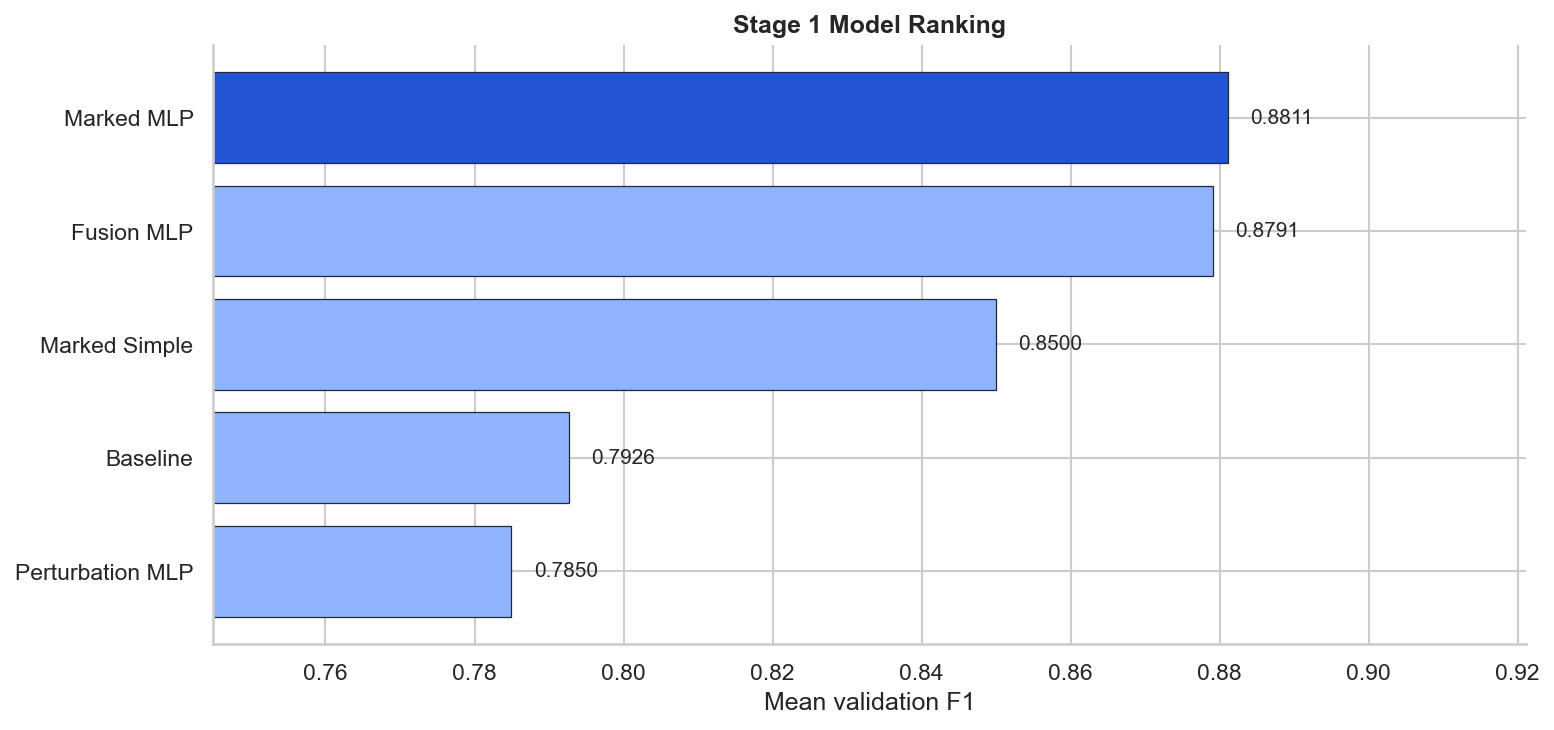

In [4]:
plot_df = summary.sort_values("mean_val_f1", ascending=True)
colors = ["#8fb3ff" if label != summary.iloc[0]["label"] else "#2454d6" for label in plot_df["label"]]

fig, ax = plt.subplots(figsize=(10.5, 5.0))
ax.barh(plot_df["label"], plot_df["mean_val_f1"], color=colors, edgecolor="#1f2937", linewidth=0.6)

for index, value in enumerate(plot_df["mean_val_f1"]):
    ax.text(value + 0.003, index, f"{value:.4f}", va="center", fontsize=10)

ax.set_xlim(max(0.0, plot_df["mean_val_f1"].min() - 0.04), min(1.0, plot_df["mean_val_f1"].max() + 0.04))
ax.set_xlabel("Mean validation F1")
ax.set_ylabel("")
ax.set_title("Stage 1 Model Ranking")
plt.tight_layout()
plt.show()


## Metric Profile

The supporting metrics show whether the F1 ranking is consistent with broader classification behavior.


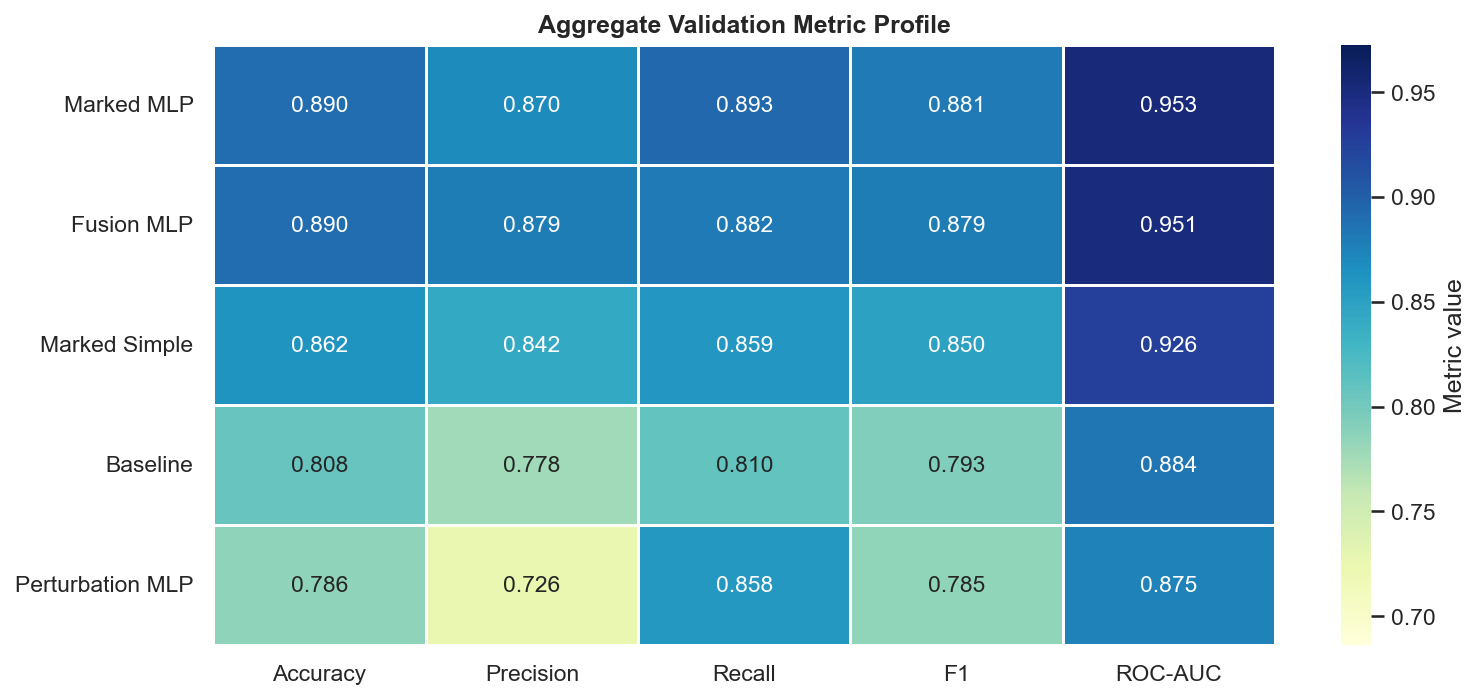

In [5]:
metric_cols = ["mean_accuracy", "mean_precision", "mean_recall", "mean_f1", "mean_roc_auc"]
metric_labels = ["Accuracy", "Precision", "Recall", "F1", "ROC-AUC"]
metric_df = summary.set_index("label")[metric_cols].rename(columns=dict(zip(metric_cols, metric_labels)))

fig, ax = plt.subplots(figsize=(10.5, 4.8))
sns.heatmap(
    metric_df,
    annot=True,
    fmt=".3f",
    cmap="YlGnBu",
    vmin=max(0.0, metric_df.min().min() - 0.04),
    vmax=min(1.0, metric_df.max().max() + 0.02),
    linewidths=0.6,
    linecolor="white",
    cbar_kws={"label": "Metric value"},
    ax=ax,
)
ax.set_title("Aggregate Validation Metric Profile")
ax.set_xlabel("")
ax.set_ylabel("")
plt.tight_layout()
plt.show()


## Margin Against Baselines

The delta table quantifies each model's improvement over the simplest baseline and over the perturbation-only model.


In [6]:
baseline_f1 = float(summary.loc[summary["model"] == "baseline", "mean_val_f1"].iloc[0])
perturbation_f1 = float(summary.loc[summary["model"] == "perturbation_mlp", "mean_val_f1"].iloc[0])
leader_f1 = float(summary["mean_val_f1"].max())

margin_table = summary[["label", "mean_val_f1"]].copy()
margin_table["delta_vs_baseline"] = margin_table["mean_val_f1"] - baseline_f1
margin_table["delta_vs_perturbation"] = margin_table["mean_val_f1"] - perturbation_f1
margin_table["gap_to_best"] = leader_f1 - margin_table["mean_val_f1"]

display(
    margin_table.style.format({
        "mean_val_f1": "{:.4f}",
        "delta_vs_baseline": "+{:.4f}",
        "delta_vs_perturbation": "+{:.4f}",
        "gap_to_best": "{:.4f}",
    })
)


,label,mean_val_f1,delta_vs_baseline,delta_vs_perturbation,gap_to_best
0,Marked MLP,0.8811,+0.0885,+0.0961,0.0000
1,Fusion MLP,0.8791,+0.0865,+0.0942,0.0019
2,Marked Simple,0.8500,+0.0574,+0.0651,0.0311
3,Baseline,0.7926,+0.0000,+0.0077,0.0885
4,Perturbation MLP,0.7850,+-0.0077,+0.0000,0.0961


## Context vs Perturbation Signals

This comparison separates marked-context representations from perturbation-based representations and their fusion.


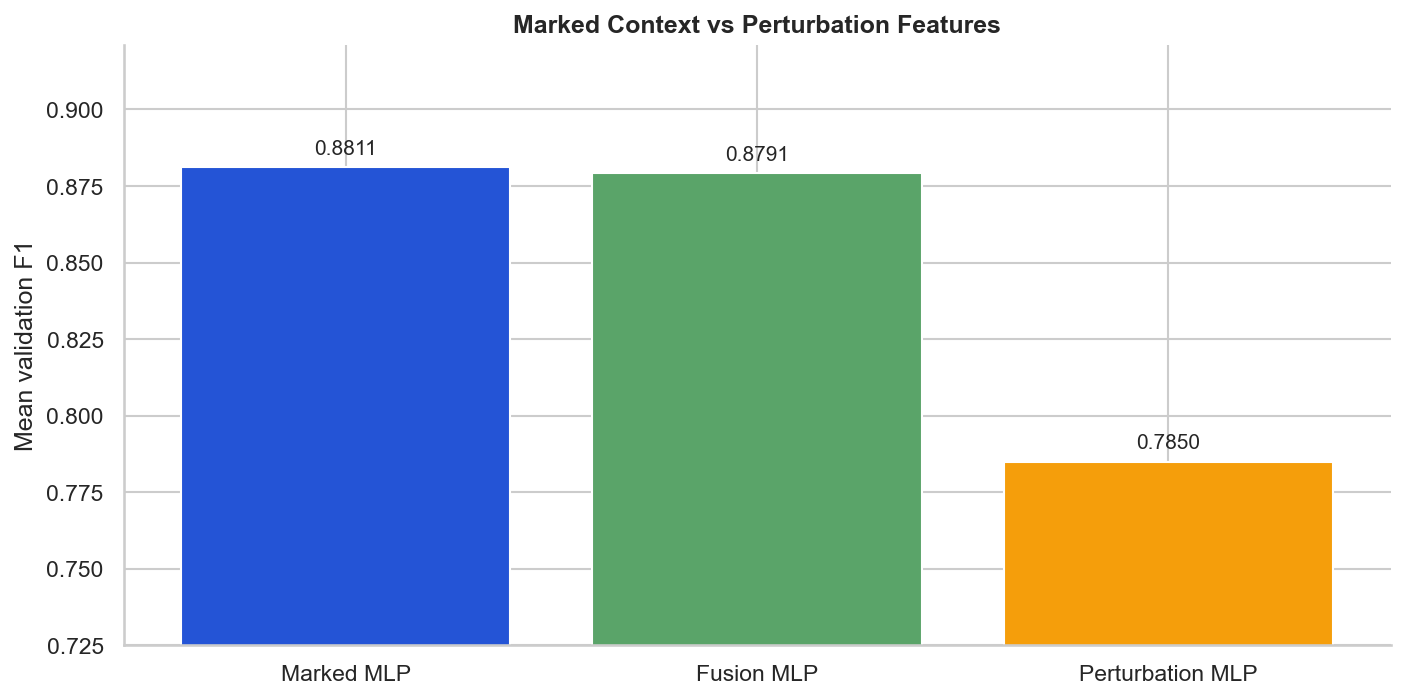

,label,input,mean_val_f1,mean_accuracy,mean_recall,mean_roc_auc
0,Marked MLP,Marked sentence embedding,0.8811,0.8903,0.8934,0.9525
1,Fusion MLP,Marked embedding + perturbation difference vectors,0.8791,0.8898,0.8815,0.9507
4,Perturbation MLP,LLM perturbation difference vectors,0.7850,0.7858,0.8579,0.8754


In [7]:
focus = summary[summary["model"].isin(["marked_mlp", "perturbation_mlp", "fusion_mlp"])].copy()
focus = focus.sort_values("mean_val_f1", ascending=False)

fig, ax = plt.subplots(figsize=(9.5, 4.8))
bars = ax.bar(focus["label"], focus["mean_val_f1"], color=["#2454d6", "#5aa469", "#f59e0b"][:len(focus)])

for bar in bars:
    height = bar.get_height()
    ax.text(bar.get_x() + bar.get_width() / 2, height + 0.003, f"{height:.4f}", ha="center", va="bottom", fontsize=10)

ax.set_ylim(max(0.0, focus["mean_val_f1"].min() - 0.06), min(1.0, focus["mean_val_f1"].max() + 0.04))
ax.set_ylabel("Mean validation F1")
ax.set_title("Marked Context vs Perturbation Features")
plt.tight_layout()
plt.show()

focus_table = focus[["label", "input", "mean_val_f1", "mean_accuracy", "mean_recall", "mean_roc_auc"]]
display(focus_table.style.format({
    "mean_val_f1": "{:.4f}",
    "mean_accuracy": "{:.4f}",
    "mean_recall": "{:.4f}",
    "mean_roc_auc": "{:.4f}",
}))


## Selected Hyperparameters

The selected hyperparameters provide context for model capacity, regularization, and optimization settings.


In [8]:
hyperparameters = hyperparameters.set_index("model").loc[[MODEL_LABELS[m] for m in MODEL_ORDER]].reset_index()
display(hyperparameters.fillna("-").style)


,model,hidden_1,hidden_2,dropout_1,dropout_2,lr,weight_decay,batch_size,dropout
0,Baseline,1024.000000,64.000000,0.400000,0.400000,0.000100,0.001000,64,-
1,Marked Simple,-,-,-,-,0.005000,0.001000,32,0.100000
2,Marked MLP,1024.000000,64.000000,0.400000,0.200000,0.000100,0.010000,64,-
3,Perturbation MLP,256.000000,64.000000,0.300000,0.400000,0.000100,0.000010,64,-
4,Fusion MLP,1536.000000,128.000000,0.500000,0.300000,0.000100,0.010000,128,-


## Final Selection

The selected model is the highest-ranked model under the aggregate validation F1 criterion.


In [9]:
leader = summary.iloc[0]
runner_up = summary.iloc[1]
margin = leader["mean_val_f1"] - runner_up["mean_val_f1"]

selection = pd.DataFrame([
    {"field": "selected_model", "value": leader["label"]},
    {"field": "selected_mean_val_f1", "value": f"{leader['mean_val_f1']:.4f}"},
    {"field": "runner_up", "value": runner_up["label"]},
    {"field": "margin_to_runner_up", "value": f"{margin:.4f}"},
    {"field": "selected_input", "value": leader["input"]},
    {"field": "selected_head", "value": leader["head"]},
])

display(selection)


,field,value
0,selected_model,Marked MLP
1,selected_mean_val_f1,0.8811
2,runner_up,Fusion MLP
3,margin_to_runner_up,0.0019
4,selected_input,Marked sentence embedding
5,selected_head,MLP
